#FMQI

In [1]:
! pip install --quiet qiskit
! pip install --quiet pylatexenc
! pip install --quiet qiskit-aer
# ! pip install --quiet

^C


In [ ]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit import transpile, QuantumRegister
from qiskit_aer import Aer
import numpy as np
import random
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation
from keras.datasets import mnist
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, mutual_info_score, r2_score
from qiskit.circuit.library.standard_gates import RYGate, RYYGate
import cv2
import pandas as pd

In [ ]:
def hadamard(circ, n):
  for i in n:
    circ.h(i)

In [ ]:
def change(state, new_state):
  n = len(state)
  c = np.array([])
  for i in range(n):
    if state[i] != new_state[i]:
      c = np.append(c, int(i))
  print(f"C value as per the change is {c}")
  if len(c)>0:
    return c.astype(int)
  else:
    return c

In [ ]:
def binary(circ, state, new_state):
  c = change(state, new_state)
  print(f"The value of c is {c}")
  if len(c) > 0:
    circ.x(np.abs(c-5))
  else:
    pass

In [ ]:
def cnri(circ, n, t, theta):
  controls = len(n)
  cry = RYGate(2*theta).control(controls)
  aux = np.append(n, t).tolist()
  print(f'aux value is {aux}')
  circ.append(cry, aux)

def frqi(circ, n, t, angles):
  hadamard(circ, n)
  j = 0
  for i in angles:
    state = '{0:06b}'.format(j-1)
    new_state = '{0:06b}'.format(j)
    print(f'State and new_state with iteration {state, new_state, i}')
    if j == 0:
      cnri(circ, n, t, i)
    else:
      binary(circ, state, new_state)
      cnri(circ, n, t, i)
    j += 1

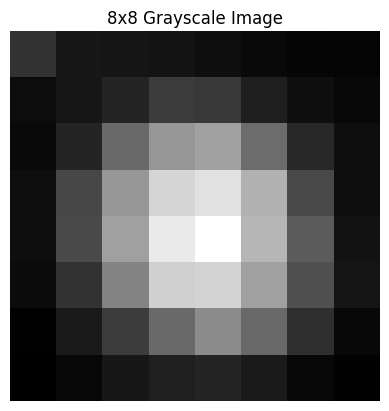

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the JPG image in grayscale mode
img = cv2.imread('../data/spiral_galaxies_1.jpg', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image not found or path is incorrect")

# Resize image to 8x8 pixels using INTER_AREA for downsampling
img_small = cv2.resize(img, (8, 8), interpolation=cv2.INTER_AREA)

# Normalize pixel values to [0, 1]
img_normalized = img_small / 255.0

# Display the resized grayscale image
plt.imshow(img_normalized, cmap='gray')
plt.title('8x8 Grayscale Image')
plt.axis('off')  # Optional: hide axis ticks
plt.show()

In [ ]:
# Flatten normalized 8x8 image to a vector of 64 pixels
flat_pixels = img_normalized.flatten()

# Compute FRQI angles by arcsin of normalized pixel values
angles = np.arcsin(flat_pixels)


In [ ]:
qr = QuantumRegister(7, 'q')
cr = ClassicalRegister(7, 'c')
qc = QuantumCircuit(qr, cr)
frqi(qc, [0, 1, 2, 3, 4, 5], 6, angles)

State and new_state with iteration ('-00001', '000000', np.float64(0.1734169204285848))
aux value is [0, 1, 2, 3, 4, 5, 6]
State and new_state with iteration ('000000', '000001', np.float64(0.09819695261883929))
C value as per the change is [5.]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
State and new_state with iteration ('000001', '000010', np.float64(0.09031882417331834))
C value as per the change is [4. 5.]
The value of c is [4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
State and new_state with iteration ('000010', '000011', np.float64(0.0863818976019207))
C value as per the change is [5.]
The value of c is [5]
aux value is [0, 1, 2, 3, 4, 5, 6]
State and new_state with iteration ('000011', '000100', np.float64(0.07064698711165317))
C value as per the change is [3. 4. 5.]
The value of c is [3 4 5]
aux value is [0, 1, 2, 3, 4, 5, 6]
State and new_state with iteration ('000100', '000101', np.float64(0.05885750594708123))
C value as per the change is [5.]
The value of c is [5

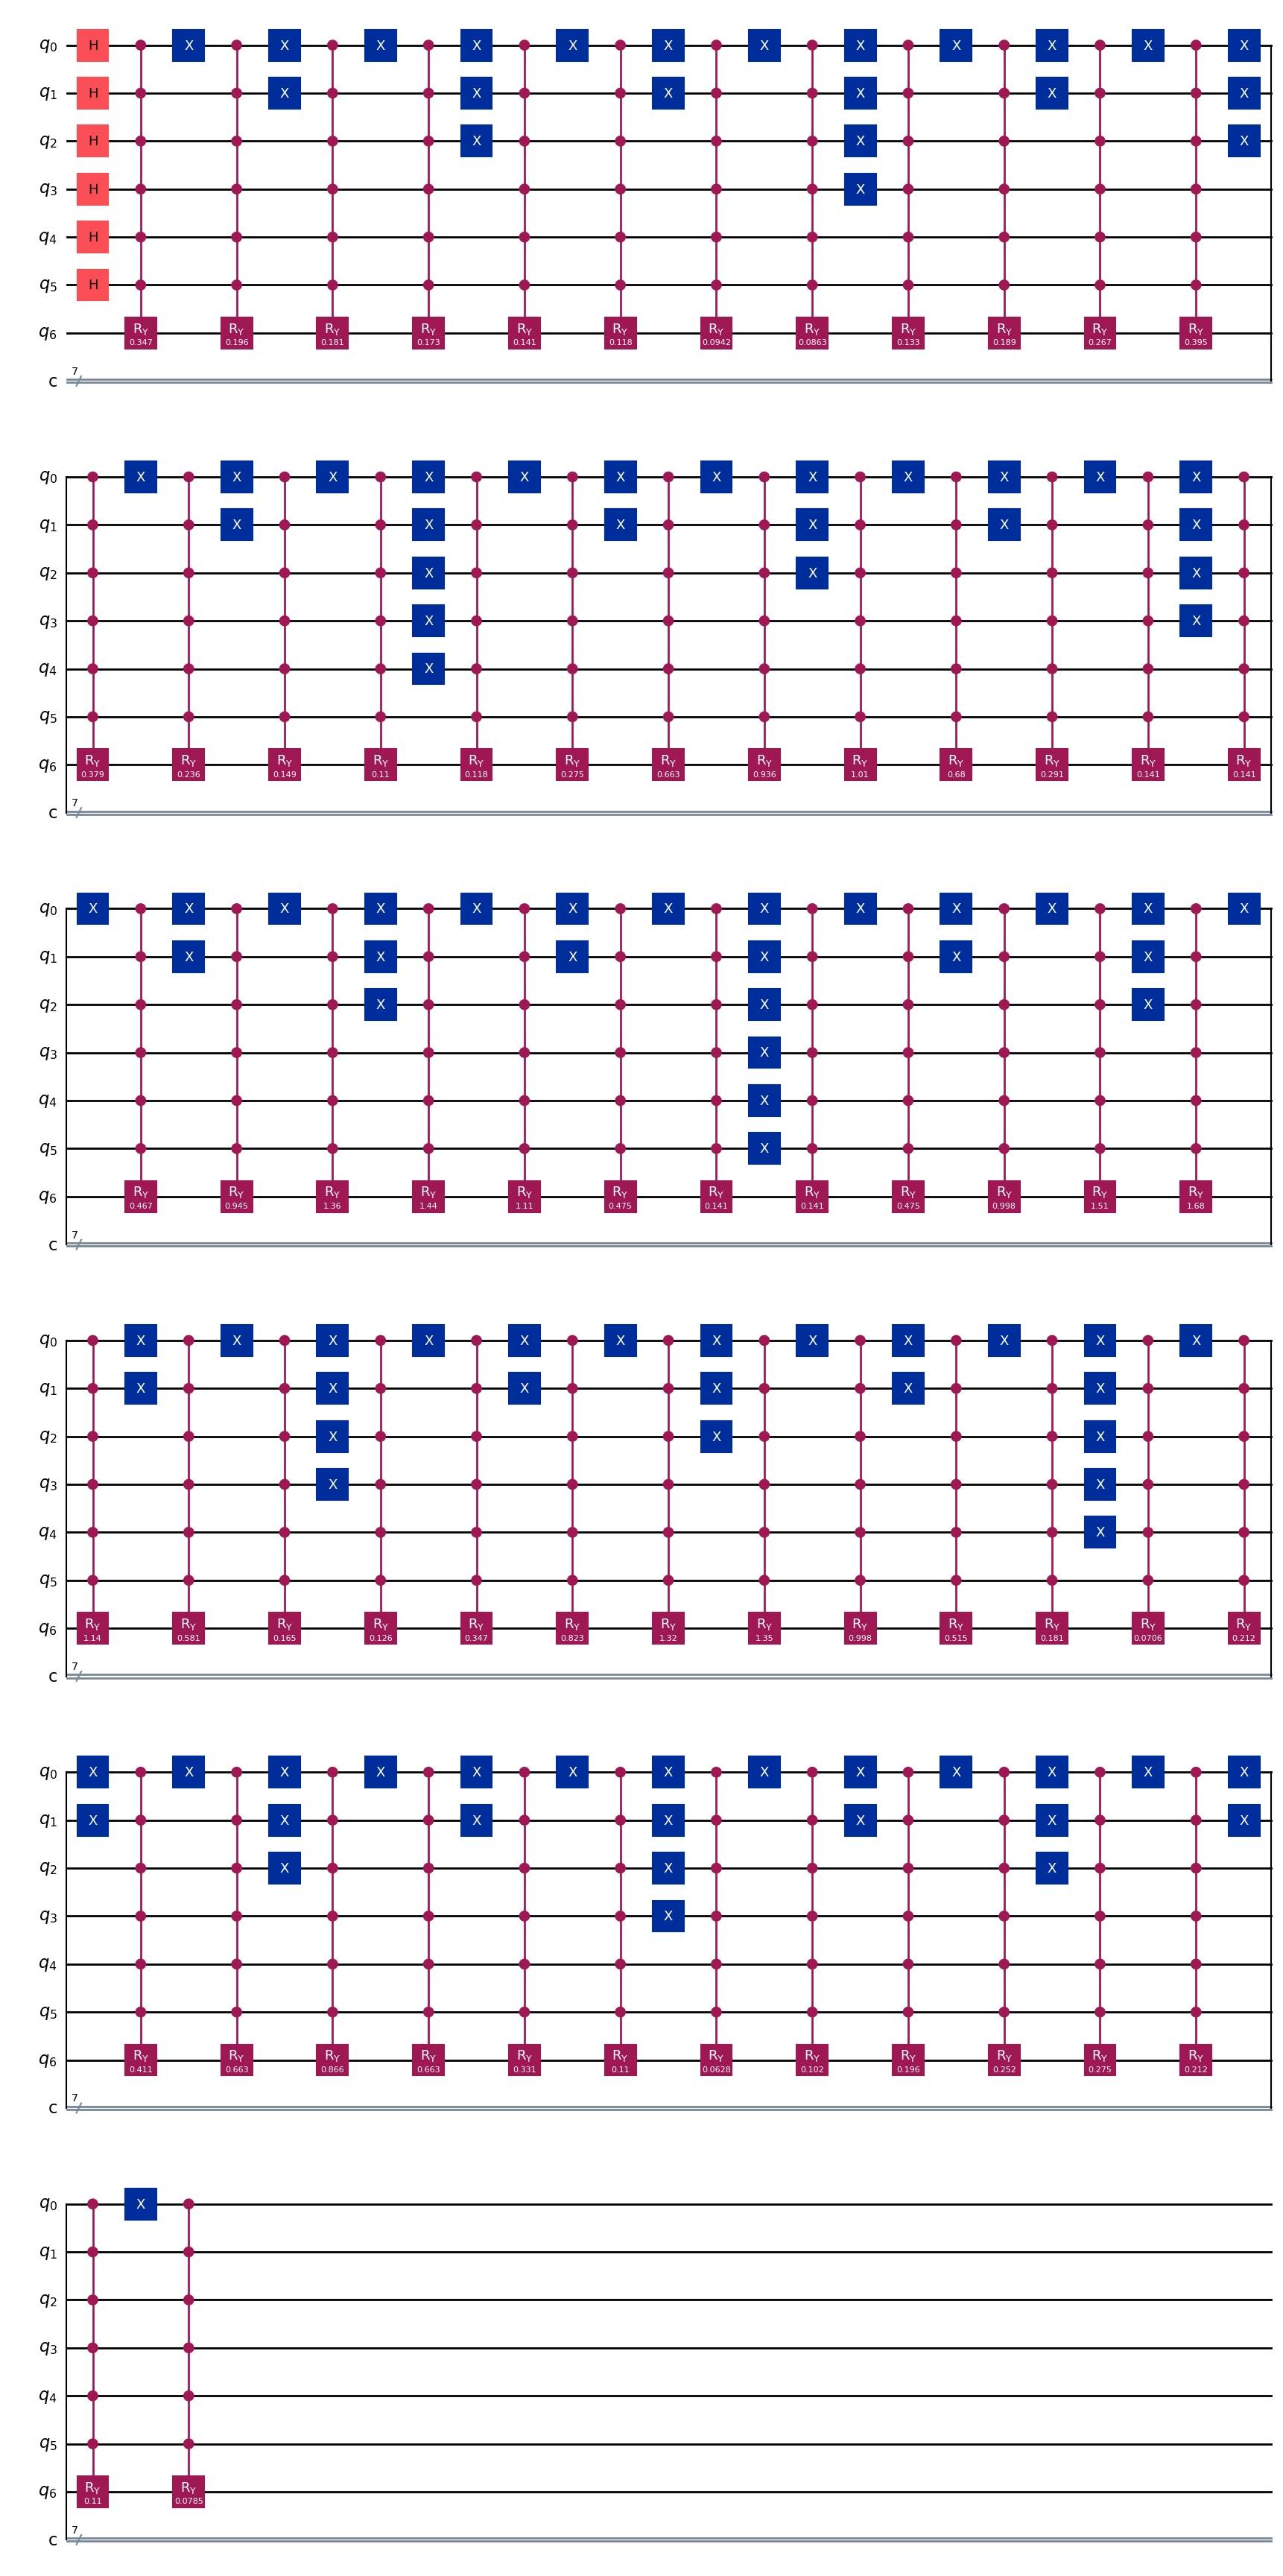

In [ ]:
qc.draw(output='mpl')

In [ ]:
qc.measure([0, 1, 2, 3, 4, 5, 6], [0, 1, 2, 3, 4, 5, 6])

In [ ]:
simulator = Aer.get_backend('aer_simulator')
transpiled_circuit = transpile(qc, backend=simulator)
result = simulator.run(transpiled_circuit, shots=20000)
counts = result.result().get_counts()
num_shots = sum(counts.values())
print(counts)

{'0110101': 274, '0101011': 169, '0000010': 293, '0010100': 262, '0111111': 300, '0100001': 305, '0001010': 285, '0001001': 320, '1010100': 65, '0011000': 286, '0110111': 311, '0000000': 305, '0100111': 307, '0111010': 308, '0100110': 289, '0001111': 336, '0101111': 301, '0110001': 307, '0000110': 331, '0110011': 252, '0101101': 250, '0000100': 320, '0100100': 157, '0111100': 295, '0001101': 288, '0111001': 321, '1010011': 67, '1110011': 26, '0100000': 319, '0111110': 292, '0100010': 262, '0001011': 322, '0111011': 303, '0100101': 233, '0001110': 286, '0000111': 340, '0110000': 297, '0111101': 322, '0100011': 156, '1000111': 2, '1111011': 10, '0101010': 250, '0110110': 286, '0000001': 327, '1100110': 24, '0010110': 280, '1101100': 112, '1100010': 78, '0011001': 265, '1101011': 113, '0010111': 336, '0001000': 300, '0011110': 324, '0011011': 214, '0101001': 307, '0010000': 297, '0111000': 294, '1011011': 130, '0101100': 186, '0110100': 260, '0000011': 330, '0000101': 289, '0110010': 312,

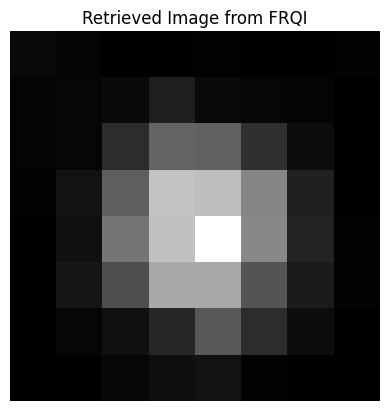

In [ ]:
retrieve_image = np.zeros(64)

for i in range(64):
    s = format(i, '06b')
    new_s = '1' + s
    prob = counts.get(new_s, 0) / num_shots
    retrieve_image[i] = prob

# Normalize and scale
retrieve_image /= retrieve_image.max()  # normalize to 1
retrieve_image *= 1.15 * 255  # scale to full brightness range
retrieve_image = retrieve_image.astype(int).reshape((8, 8))

plt.imshow(retrieve_image, cmap='gray', vmin=0, vmax=255)
plt.title('Retrieved Image from FRQI')
plt.axis('off')
plt.show()




#NEQR

In [ ]:
! pip install --quiet qiskit
! pip install --quiet pylatexenc
! pip install --quiet qiskit-aer

In [ ]:
#Importing Necessary Libraries

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit import transpile, QuantumRegister
from qiskit_aer import Aer
import numpy as np
import qiskit
import random
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation
from keras.datasets import mnist
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, mutual_info_score, r2_score
from qiskit.circuit.library.standard_gates import RYGate, RYYGate, MCXGate
import cv2
import pandas as pd

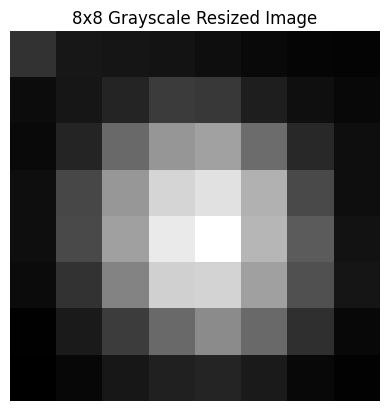

In [ ]:
import cv2

# Load JPG image in grayscale mode
img = cv2.imread('../data/spiral_galaxies_1.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError("Image not found or path is incorrect")

# Resize image to 8x8 pixels
img_small = cv2.resize(img, (8, 8), interpolation=cv2.INTER_AREA)

# Optional: show the resized image to verify
plt.imshow(img_small, cmap='gray')
plt.title('8x8 Grayscale Resized Image')
plt.axis('off')
plt.show()

# Use this resized image for NEQR encoding
images = np.array([img_small])


[[101 176 158 254  50 174 185  87]
 [ 64  20 193 145 247  32 253 166]
 [ 82 188 222  81 110 194 239 236]
 [157  50 252 111  27  17 221 132]
 [  7  19   5 183 112 108 188  25]
 [ 86 160 181  99  80 110 119  23]
 [121 120 179 128  89 204 246  27]
 [ 83 172  56  64 111 178  45 105]]


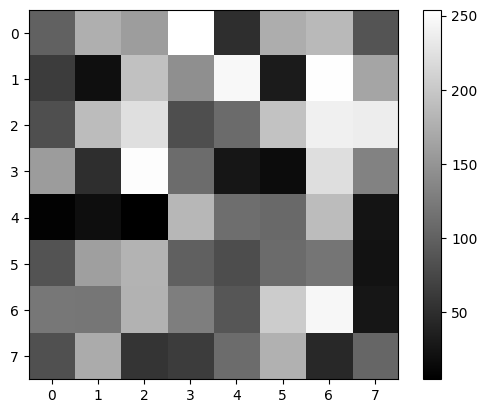

In [ ]:
import numpy as np

# Generate an 8x8 array with random values between 0 and 255 (inclusive)
random_array = np.random.randint(0, 256, size=(8,8))

# Visualization of the random array generated
print(random_array)
plt.imshow(random_array, cmap='gray')
plt.colorbar()
plt.show()



In [ ]:
#Applying Hadamard Gate for qubits used for pixel location
def hadamard(circ, n):
  for i in n:
    circ.h(i)

In [ ]:
from os import name
import math


print(images.shape)

# Using qubit properties, we can represent 2**n values using n qubits
n = int(math.log2(images[0].shape[0]))
q = 8


def SetState(qc, position_x, position_y, q, intensity):
  for i in range(n):
    if position_y[i] == '0':
      qc.x(q + i)
  for i in range(n):
    if position_x[i] == '0':
      # print(n, q, i)
      qc.x(q + n + i)

  control_bits = []
  for i in range(2 * n):
    control_bits.append(q+i)

  intensity = intensity[::-1]
  for i in range(len(intensity)):
    if intensity[i] == '1':
      qc.mcx(control_bits, i)

  for i in range(n):
    if position_y[i] == '0':
      qc.x(q + i)
  for i in range(n):
    if position_x[i] == '0':
      qc.x(q + n + i)


  return qc

def neqr(n, q):
  hadamard_gates = []
  qc = QuantumCircuit(2*n+q, 2*n+q)
  for i in range(2*n + q):
    if i >= q:
      hadamard_gates.append(i)
  hadamard(qc, hadamard_gates)
  qc.barrier()
  for i in range(len(images[0])):
    for j in range(len(images[0][0])):
      position_x = bin(i)[2:].zfill(n)
      position_y = bin(j)[2:].zfill(n)
      intensity = bin(int(images[0][i][j]))[2:].zfill(q)
      qc = SetState(qc, position_x, position_y, q, intensity)
      qc.barrier()
  return qc

qc = neqr(n, q)
qc.measure([i for i in range(2*n + q)], [i for i in range(2*n +q)])
# qc.draw(output="mpl")

(1, 8, 8)


In [ ]:
simulator = Aer.get_backend('aer_simulator')
transpiled_circuit = transpile(qc, backend=simulator)
result = simulator.run(transpiled_circuit, backend=simulator, shots=20000)
counts = result.result().get_counts()
print(counts)
print(len(counts))

{'00110000111100': 320, '00110110001010': 313, '00011100001011': 326, '11011010100000': 356, '11110100011011': 285, '11101000011001': 300, '10100110011111': 295, '11010000111011': 320, '01101100101010': 294, '10100000010000': 315, '11100000001000': 320, '11100100100011': 305, '01000000001111': 316, '00101101001001': 272, '10110101111010': 333, '11110000001101': 333, '10111100010111': 293, '01111100001110': 296, '10011000110010': 326, '00111010101111': 338, '11111100001010': 303, '00001100001100': 304, '00000000101100': 319, '10000000010001': 314, '00001000010111': 306, '00111100010101': 287, '01010000100011': 348, '10101001100110': 321, '01001100100101': 316, '01101000110100': 315, '10111010011100': 327, '11011100010010': 307, '01000101111011': 313, '10101101000001': 301, '01110000011011': 297, '11000000010010': 292, '01111001010011': 338, '01011100010010': 275, '10110000101100': 317, '11001100111100': 311, '00010000011001': 314, '01010101010101': 333, '11101100001110': 306, '110101100



In [ ]:
qc.draw(output='mpl')

(8, 8) 3


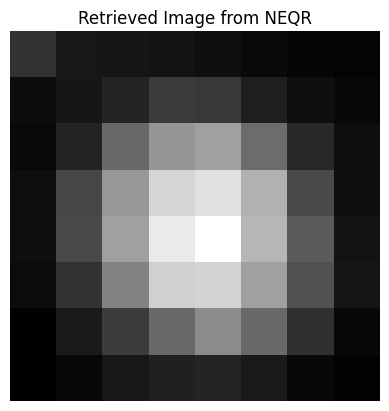

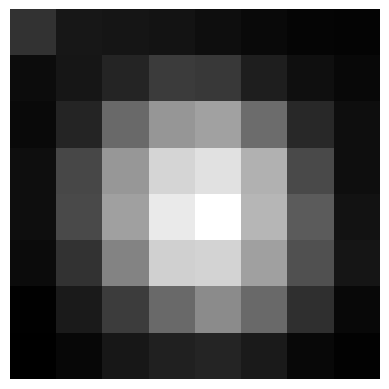

In [ ]:
import numpy as np
from PIL import Image

restored_image = np.random.randint(0, 256, size=(2**n, 2**n))
print(restored_image.shape, n)

for value in counts:
  x_coordinate = int(value[:n][::-1], 2)
  y_coordinate = int(value[n:2*n][::-1], 2)
  intensity = int(value[2*n:],2)
  restored_image[x_coordinate][y_coordinate] = intensity


#Depicting both images
plt.imshow(restored_image, cmap='gray')
plt.axis('off')
plt.title('Retrieved Image from NEQR')
plt.show()


plt.imshow(images[0], cmap='gray')
plt.axis('off')
plt.show()